### 6. Investigate the impact of feature scaling and normalization on perceptron training. Use a dataset with varying scales and demonstrate how normalizaiton affects the convergence of the perceptron.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([
    [1,  1000],
    [2,  1500],
    [3,  2000],
    [4,  2500],
    [5,  3000],
    [6,  3500]
])

Y = np.array([0, 0, 0, 1, 1, 1])

In [3]:
class Perceptron:

    def __init__(self, lr=0.01):
        self.w = np.zeros(2)
        self.b = 0
        self.lr = lr
        self.errors = []

    def predict(self, x):
        return 1 if (np.dot(x, self.w) + self.b) >= 0 else 0

    def fit(self, X, Y, epochs):
        for _ in range(epochs):
            err_count = 0
            for x, y in zip(X, Y):
                y_hat = self.predict(x)
                err = y - y_hat
                if err != 0:
                    self.w = self.w + self.lr * err * x
                    self.b = self.b + self.lr * err
                    err_count += 1
            self.errors.append(err_count)

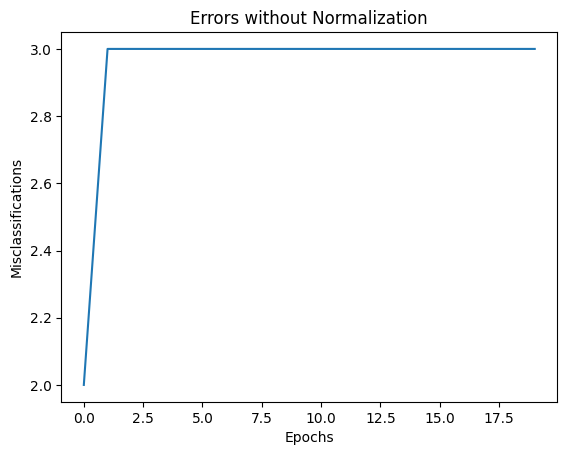

In [4]:
p1 = Perceptron()
p1.fit(X, Y, epochs=20)

plt.plot(p1.errors)
plt.title("Errors without Normalization")
plt.xlabel("Epochs")
plt.ylabel("Misclassifications")
plt.show()

##### With Normalization

In [5]:
X_norm = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

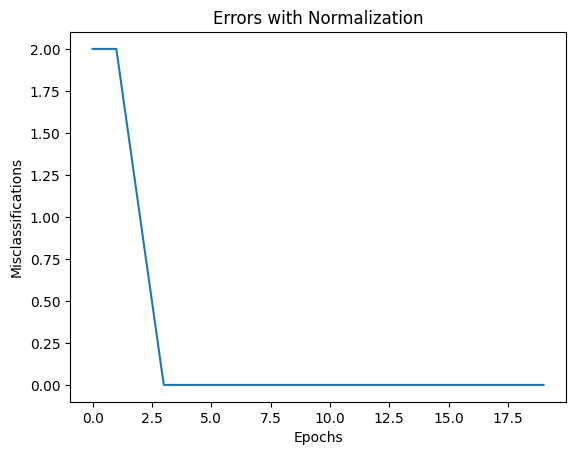

In [6]:
p2 = Perceptron()
p2.fit(X_norm, Y, epochs=20)

plt.plot(p2.errors)
plt.title("Errors with Normalization")
plt.xlabel("Epochs")
plt.ylabel("Misclassifications")
plt.show()